![Banner](../images/03_08_banner_spatial_analysis_capstone.png)

# Land Suitability for Wheat in Bangladesh


This is Capstone 3 of the spatial analysis module (Part 7). It builds a national land-suitability map for dry-season wheat in Bangladesh at 250 m, using the FAO framework from 03.04: criteria, constraints, fuzzy memberships, AHP weights and suitability classes.

**Data:** climate, land, soil and constraint layers in `data/Wheat_suitability`.

**Library:** `geolattice.spatial_analysis`

## Overview

Wheat is the second cereal of Bangladesh after rice. It is a **rabi** (dry-season) crop: sown from mid-November to early December on land that has drained after the monsoon, irrigated two or three times, and harvested in March. Two things decide where it does well. The land must be **free of water and workable in time for sowing**, and the crop must **fill its grain before the heat of March**: every degree of warming during grain filling costs yield, which is why wheat is concentrated in the cooler north-west.

This capstone builds a national **land suitability map for wheat** at **250 m** resolution following the FAO land-evaluation framework (Module 03.04):

- **criteria** for climate (season and grain-filling temperature), land (land type, drainage, slope), soil (pH, organic carbon) and water (depth to groundwater for irrigation, drought class);
- **constraints** that rule land out (water bodies, settlements, forest, hills, problem soils);
- **fuzzy membership functions** that turn each criterion into a score from 0 to 1;
- **AHP weights** and three ways of combining the scores (weighted linear combination, weighted fuzzy gamma, limiting factor);
- **FAO suitability classes** S1, S2, S3, N1 and N2, summarised by district and upazila;
- a **validation** against the districts that grow most of the country's wheat, and **uncertainty** analysis of the weights and of year-to-year heat.

The notebook also contains a real data-quality problem: the temperature grids in the folder are stored **upside down**. Section 4 shows how it was found and how it is corrected.

## Overview

| Stage | Question | Main tools |
|---|---|---|
| **Data and grid** | What is in the folder, and on which grid? | `AnalysisGrid`, `warp_to_grid` |
| **Temperature check** | Are the temperature grids right? | latitude test, row flip, trend and residual gap-fill, hold-out test |
| **Climate criteria** | How warm is the season and the grain-filling period? | 18 seasons of 16-day 2 m temperature |
| **Land, soil and water criteria** | Which land drains in time, has good soil and can be irrigated? | soil-survey rasters, `slope` |
| **Constraints** | Which land is ruled out? | `categorical_and` |
| **Memberships and weights** | How is each criterion scored and weighted? | `trapezoidal_mf`, `linear`, `small`, AHP |
| **Combination** | How do the scores add up? | `weighted_linear_combination`, `weighted_fuzzy_overlay`, minimum, `limiting_criterion`, `score_contributions` |
| **Classes** | How much land is S1, S2, S3, N1, N2? | FAO classes, district and upazila summaries |
| **Validation** | Does the map find the wheat districts? | district ranking, AUC |
| **Uncertainty** | How stable is the map to weights and to a hot year? | `monte_carlo_weights`, `jaccard_index`, heat-year frequency |

### What this notebook reuses

| Topic | Notebook |
|---|---|
| Fuzzy membership and weighted overlay | [`03_04_02_00_fuzzy_logic_foundations.ipynb`](../03_04_multi_criteria_suitability_analysis/03_04_02_00_fuzzy_logic_foundations.ipynb), [`03_04_01_03_weighted_suitability.ipynb`](../03_04_multi_criteria_suitability_analysis/03_04_01_03_weighted_suitability.ipynb) |
| Weight uncertainty | [`03_04_03_sensitivity_uncertainty.ipynb`](../03_04_multi_criteria_suitability_analysis/03_04_03_sensitivity_uncertainty.ipynb) |
| Terrain derivatives | [`03_02_02_terrain_analysis.ipynb`](../03_02_digital_terrain_modeling/03_02_02_terrain_analysis.ipynb) |
| The same national soil and land-type layers in a flood study | [`03_08_01_flood_susceptibility_mapping.ipynb`](03_08_01_flood_susceptibility_mapping.ipynb) |

## Table of Contents

1. [Setup](#setup)
2. [Problem statement](#problem-statement)
3. [The data and one analysis grid](#the-data-and-one-analysis-grid)
4. [Checking the temperature grids](#checking-the-temperature-grids)
5. [Climate criteria](#climate-criteria)
6. [Land, soil and water criteria](#land-soil-and-water-criteria)
7. [Constraints](#constraints)
8. [Fuzzy memberships](#fuzzy-memberships)
9. [AHP weights](#ahp-weights)
10. [Combining the criteria](#combining-the-criteria)
11. [FAO suitability classes](#fao-suitability-classes)
12. [What limits wheat where](#what-limits-wheat-where)
13. [Validation against the wheat districts](#validation-against-the-wheat-districts)
14. [Uncertainty](#uncertainty)
15. [District and upazila summaries](#district-and-upazila-summaries)
16. [Outputs](#outputs)
17. [Limitations](#limitations)
18. [Where to go next](#where-to-go-next)

## Setup

**Installation.** This notebook needs installation option 2 (core plus spatial analysis): `pip install "geolattice[analysis]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

# Standard library imports.
import sys  # make the capstone helper module importable
import time  # report how long the heavier steps take
import warnings  # silence harmless warnings
from pathlib import Path  # filesystem paths

# Third-party numeric / geospatial / plotting stack.
import geopandas as gpd  # district and upazila boundaries
import matplotlib.pyplot as plt  # maps and charts
import numpy as np  # arrays
import pandas as pd  # tables
from IPython.display import display  # rich table previews
from matplotlib.colors import ListedColormap  # class maps
from osgeo import gdal  # raw access to the 1 km temperature grids
from rasterio import features, transform  # burn district ids into the grid
from scipy import ndimage  # gap filling and smoothing
from sklearn.metrics import roc_auc_score  # district-level validation

# Shared capstone helpers live next to this notebook.
sys.path.insert(0, str(Path.cwd()))
import data_processing as dp  # paths, analysis grid, warping helpers

import geolattice

ROOT = Path(geolattice.__file__).resolve().parents[1]
if not (ROOT / "Data").is_dir():
    ROOT = dp.find_repo_root()

# GeoLattice tools.
from geolattice.spatial_analysis import (
    categorical_and,  # all constraints must pass
    jaccard_index,  # overlap of two class masks
    limiting_criterion,  # name of the weakest criterion per cell
    linear,  # linear ramp membership
    monte_carlo_weights,  # Dirichlet weight uncertainty
    score_contributions,  # w_i * x_i per criterion
    slope,  # slope gradient from the DEM
    small,  # sigmoid membership, small values -> 1
    trapezoidal_mf,  # trapezoidal membership with an optimum plateau
    weighted_fuzzy_overlay,  # weighted fuzzy gamma
    weighted_linear_combination,  # weighted linear combination
)
from geolattice.viz import apply_map_style

apply_map_style()
gdal.UseExceptions()
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.precision", 3)

SRC = ROOT / "Data" / "03_spatial_analysis" / "Wheat_suitability"
TEMP = SRC / "Temperature"
UPAZILA = ROOT / "Data" / "00_shared" / "vector_data" / "Bangladesh" / "Shapefiles" / "bd_upzila_GCS.shp"
OUT = dp.capstone_dir(ROOT, "wheat_suitability")
print(f"Inputs:  {SRC}")
print(f"Outputs: {OUT}")

Inputs:  /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/Wheat_suitability
Outputs: /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/capstone_spatial_analysis/wheat_suitability


## Problem statement

**The crop calendar.** Wheat in Bangladesh is sown from about 15 November to 5 December and harvested from mid-March to early April, a season of roughly 110 to 120 days. Sowing waits until the land has drained after the monsoon; sowing late pushes grain filling into the hot second half of March.

**What limits it.**

- *Heat during grain filling* (mid-February to March) is the main climatic limit. The north-west (Panchagarh, Thakurgaon, Dinajpur) has the coolest and longest winter of the country.
- *Land type and drainage*: lowland that is still wet in November cannot be sown in time.
- *Soil*: wheat prefers near-neutral soils; strongly acid terrace and hill soils reduce yield.
- *Water*: two or three irrigations are needed. Shallow tubewells serve land with a shallow water table; the Barind Tract relies on deep tubewells.

**Where it is grown.** According to the Bangladesh Wheat and Maize Research Institute, 14 districts produce about 90 % of the country's wheat: Thakurgaon, Chapainawabganj, Natore, Rajshahi, Pabna, Faridpur, Naogaon, Panchagarh, Meherpur, Kushtia, Rajbari, Bhola, Kurigram and Dinajpur (*The Daily Star*, 16 August 2025). This list is the reference for the validation in Section 13. It reflects where farmers *choose* wheat, which also depends on prices and on competing crops such as boro rice, maize and potato; a suitability map should agree with it broadly, not perfectly.

**Question.** Where in Bangladesh is land physically suitable for irrigated rabi wheat, what limits it elsewhere, and how robust is that picture?

## The data and one analysis grid

| Layer | File | Native grid | Use |
|---|---|---|---|
| Elevation | `DEM.tif` | 250 m | slope, constraint |
| Land type | `LT.tif` | 250 m | criterion |
| Drainage class | `DRC.tif` | 250 m | criterion |
| Soil pH | `pH.tif` | 250 m | criterion |
| Organic carbon (%) | `OC.tif` | 250 m | criterion |
| Drought class | `DROUGHT.tif` | 250 m | criterion |
| General soil type, AEZ | `STYPE.tif`, `AEZ.tif` | 250 m | constraints |
| Texture, permeability, slope class, depth class, thermal zone | `TEX.tif`, `SPC.tif`, `HFC.tif`, `SDC.tif`, `exTZONE.tif` | 250 m | described, not used (see Section 6.4) |
| 2 m temperature: mean, hourly minimum, hourly maximum | `Temperature/t2m`, `mn2t`, `mx2t`, 16-day composites 2000 to 2018 | about 1 km | climate criteria |
| Depth to water table | `Watertable_2020/`, 16-day 2020 | about 1 km | criterion |
| NDVI, population, land use 2020, monthly rainfall 1901 to 2018 | `NDVI/`, `population_2020.tif`, `landuse_2020.tif`, `Total_rainfall/` | various | not needed for this model |

All national 250 m rasters share one grid: a transverse Mercator projection on WGS 84 with central meridian 90 °E, 1,919 x 2,680 cells. That grid is used as the **analysis grid**, so the 250 m layers are read without resampling and only the 1 km layers are interpolated (bilinear).

In [2]:
dem_ds = gdal.Open(str(SRC / "DEM.tif"))
gt = dem_ds.GetGeoTransform()
GRID = dp.AnalysisGrid(gt[0], gt[3] - dem_ds.RasterYSize * 250.0, gt[0] + dem_ds.RasterXSize * 250.0, gt[3],
                       250.0, dem_ds.GetProjection())
print(f"Analysis grid: {GRID.shape[0]} rows x {GRID.shape[1]} columns of {GRID.res:.0f} m")

LAYERS = {name: dp.warp_to_grid(SRC / f"{name}.tif", GRID) for name in
          ["DEM", "LT", "DRC", "pH", "OC", "DROUGHT", "STYPE", "AEZ", "TEX", "SPC", "HFC", "SDC", "exTZONE"]}
LAND = np.isfinite(LAYERS["DEM"])
print(f"Land cells: {LAND.sum():,} ({LAND.sum() * 0.0625:,.0f} km²)")

LT_NAMES = pd.read_csv(SRC / "IDFILES" / "LT_ID.csv").set_index("LT_ID").LT_Class.to_dict()
DRC_NAMES = pd.read_csv(SRC / "IDFILES" / "DRC_ID.csv").set_index("DRC").DRC_CLASS.to_dict()
DROUGHT_NAMES = pd.read_csv(SRC / "IDFILES" / "DROUT_ID.csv").set_index("DROUT_ID").DROUT_Class.to_dict()
STYPE_NAMES = pd.read_csv(SRC / "IDFILES" / "STYPE_ID.csv").groupby("STYPE").General_Soil_type.apply("; ".join).to_dict()
AEZ_NAMES = pd.read_csv(SRC / "IDFILES" / "AEZ_ID.csv").groupby("AEZ").AEZ_NAME.apply("; ".join).to_dict()

# Districts and upazilas, in the CRS of the grid.
upz = gpd.read_file(UPAZILA).to_crs(GRID.crs)[["ADM3_EN", "ADM3_PCODE", "ADM2_EN", "ADM1_EN", "geometry"]]
dist = upz.dissolve("ADM2_EN", as_index=False)[["ADM2_EN", "geometry"]]
tr = transform.from_origin(GRID.xmin, GRID.ymax, GRID.res, GRID.res)
DIST_ID = features.rasterize(((g, i + 1) for i, g in enumerate(dist.geometry)), out_shape=GRID.shape, transform=tr)
UPZ_ID = features.rasterize(((g, i + 1) for i, g in enumerate(upz.geometry)), out_shape=GRID.shape, transform=tr)
print(f"{len(dist)} districts, {len(upz)} upazilas")


def show(ax, arr, title, cmap="viridis", vmin=None, vmax=None, outlines=True):
    """Map one national grid with district outlines."""
    im = ax.imshow(np.where(LAND, arr, np.nan), extent=GRID.extent, cmap=cmap, vmin=vmin, vmax=vmax,
                   interpolation="nearest")
    if outlines:
        dist.boundary.plot(ax=ax, color="0.35", linewidth=0.25)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
    return im

Analysis grid: 2680 rows x 1919 columns of 250 m


Land cells: 2,263,520 (141,470 km²)


64 districts, 544 upazilas


## Checking the temperature grids

### Mean, minimum and maximum

The folder has three temperature variables. Their names follow ERA5: `t2m` (mean 2 m temperature), `mn2t` and `mx2t` (minimum and maximum). In ERA5, `mn2t` and `mx2t` are the extremes **within each hour**, not within each day. Averaged over 16 days they stay within about a degree of the mean, so they cannot be used for daily-maximum rules such as "days above 30 °C". The model uses `t2m`.

In [3]:
rows = []
for doy in ("001", "049", "081"):
    med = {v: np.nanmedian(gdal.Open(str(TEMP / v / f"{v}_2010_{doy}.tif")).ReadAsArray()) for v in ("mn2t", "t2m", "mx2t")}
    rows.append({"composite": f"2010, day {doy}", **{k: round(float(x), 2) for k, x in med.items()},
                 "mx2t - mn2t": round(float(med["mx2t"] - med["mn2t"]), 2)})
display(pd.DataFrame(rows).set_index("composite").rename_axis(columns="national median (°C)"))

national median (°C),mn2t,t2m,mx2t,mx2t - mn2t
composite,,,,
"2010, day 001",15.20,16.62,17.99,2.78
"2010, day 049",22.37,23.66,24.91,2.54
"2010, day 081",28.41,29.12,30.08,1.67


A daily temperature range in Bangladesh in January is 10 to 12 °C; here `mx2t - mn2t` is under 3 °C, confirming that these are hourly extremes.

### Which way is north?

A simple test of any climate grid is its gradient with latitude. In January, Bangladesh is coolest in the far north-west (Panchagarh and Thakurgaon, typically 15 to 17 °C) and warmest on the south-east coast (Cox's Bazar and Teknaf, 20 to 22 °C). The grids as stored show the opposite.

Early January mean, northern fifth of the grid: 21.0 °C; southern fifth: 14.5 °C
Mask check: share of 1 km cells where 'temperature present' matches 'land in the DEM': 98.1% as stored, 72.9% if flipped


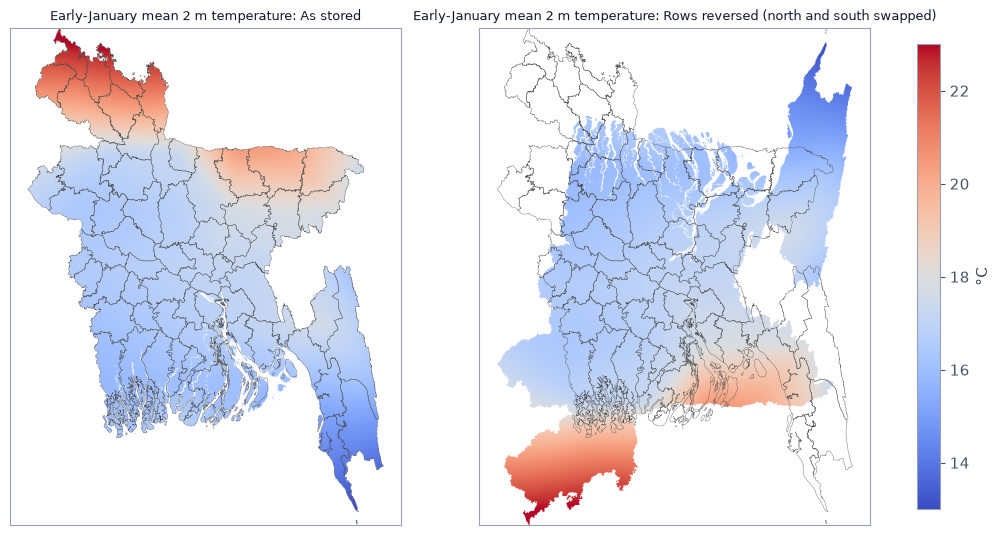

In [4]:
ref = gdal.Open(str(TEMP / "t2m" / "t2m_2010_049.tif"))
T_GT, T_WKT = ref.GetGeoTransform(), ref.GetProjection()
T_SHAPE = (ref.RasterYSize, ref.RasterXSize)
# Land mask and mean elevation on the 1 km temperature grid.
dem1 = gdal.Warp("", str(SRC / "DEM.tif"), format="MEM", width=T_SHAPE[1], height=T_SHAPE[0],
                 outputBounds=(T_GT[0], T_GT[3] + T_SHAPE[0] * T_GT[5], T_GT[0] + T_SHAPE[1] * T_GT[1], T_GT[3]),
                 resampleAlg="average", dstNodata=-9999).ReadAsArray().astype(float)
LAND1 = dem1 > -1000

jan = np.mean([gdal.Open(str(f)).ReadAsArray().astype(float) for f in sorted((TEMP / "t2m").glob("t2m_20??_001.tif"))],
              axis=0)
band = T_SHAPE[0] // 10
north, south = np.nanmean(jan[:2 * band]), np.nanmean(jan[-2 * band:])
print(f"Early January mean, northern fifth of the grid: {north:.1f} °C; southern fifth: {south:.1f} °C")
print("Mask check: share of 1 km cells where 'temperature present' matches 'land in the DEM': "
      f"{np.mean(np.isfinite(jan) == LAND1):.1%} as stored, {np.mean(np.isfinite(np.flipud(jan)) == LAND1):.1%} if flipped")

fig, axes = plt.subplots(1, 2, figsize=(12, 7))
ext1 = (T_GT[0], T_GT[0] + T_SHAPE[1] * T_GT[1], T_GT[3] + T_SHAPE[0] * T_GT[5], T_GT[3])
for ax, arr, title in zip(axes, (jan, np.flipud(jan)), ("As stored", "Rows reversed (north and south swapped)")):
    im = ax.imshow(arr, extent=ext1, cmap="coolwarm", vmin=13, vmax=23)
    dist.boundary.plot(ax=ax, color="0.3", linewidth=0.25)
    ax.set_title(f"Early-January mean 2 m temperature: {title}", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
plt.colorbar(im, ax=axes, fraction=0.025, label="°C")
plt.show()

**What this shows.** As stored, the far north is the warmest part of the country in January and the coast the coldest, which is impossible. With the rows reversed, the values follow the known pattern, but the land mask no longer fits: the values were turned upside down *before* the files were clipped to Bangladesh. This is a common error when a NetCDF file whose latitudes run south to north is written to GeoTIFF without flipping the array. The water-table grid in the same folder does not have this problem: it is deepest under the Barind Tract (Rajshahi, Naogaon, Chapainawabganj), as expected.

### Correction

The values for each land cell are recovered by reversing the rows. About a third of the land then has no value, because its mirror cell lay outside Bangladesh and was masked. Temperature at this scale is very smooth (the source reanalysis has cells of about 10 km), so the gaps are filled in two steps:

1. a **trend**: a cubic polynomial in position plus mean elevation, fitted to the recovered cells;
2. the **residuals** of the recovered cells, spread into the gaps as a Gaussian-weighted mean of nearby residuals (normalised convolution, σ = 15 km).

A hold-out test removes a 60 km wide north-south band of recovered cells, fills it the same way and compares.

In [5]:
R1, C1 = np.indices(T_SHAPE)
Y1, X1, Z1 = R1 / T_SHAPE[0], C1 / T_SHAPE[1], np.where(LAND1, dem1, 0) / 1000


def design(m):
    return np.c_[np.ones(m.sum()), Y1[m], X1[m], Y1[m] ** 2, X1[m] ** 2, X1[m] * Y1[m], Y1[m] ** 3, Z1[m]]


def correct(stored):
    """Reverse the rows of a stored 1 km grid and fill the cells lost to masking."""
    f = np.flipud(stored)
    ok = np.isfinite(f) & LAND1
    coef, *_ = np.linalg.lstsq(design(ok), f[ok], rcond=None)
    trend = (design(np.ones(T_SHAPE, bool)) @ coef).reshape(T_SHAPE)
    resid = np.where(ok, f - trend, 0.0)
    # Normalised convolution: a Gaussian-weighted mean of the residuals of nearby recovered cells.
    num = ndimage.gaussian_filter(resid, 15)
    den = ndimage.gaussian_filter(ok.astype(float), 15)
    resid_fill = np.where(den > 1e-3, num / np.maximum(den, 1e-3), 0.0)
    out = np.where(ok, f, trend + resid_fill)
    out[~LAND1] = np.nan
    r2 = 1 - np.var(resid[ok]) / np.var(f[ok])
    return out, r2, ok


fixed, r2, recovered = correct(jan)
test = recovered & (C1 > 200) & (C1 < 260)
held = np.flipud(jan).copy()
held[test] = np.nan
refill, _, _ = correct(np.flipud(held))
err = refill[test] - np.flipud(jan)[test]
print(f"Trend R²: {r2:.3f}; land cells filled: {1 - recovered[LAND1].mean():.0%}")
print(f"Hold-out band: mean absolute error {np.abs(err).mean():.2f} °C, largest {np.abs(err).max():.2f} °C")

Trend R²: 0.853; land cells filled: 32%
Hold-out band: mean absolute error 0.10 °C, largest 0.77 °C


The trend explains most of the variation (R² about 0.86 for early January) and the residual fill does the rest: in the hold-out band the mean error is under 0.1 °C and the largest under 0.8 °C, far below the 3 to 4 °C differences between regions that matter for wheat. **The correction is a workaround, not a fix:** re-exporting the temperature series with the latitude axis handled correctly is the proper solution. The function `correct` checks nothing by itself, so if corrected files replace the current ones, the call to it in the next section must be removed.

## Climate criteria

Two climate criteria are computed from 18 seasons (2000/01 to 2017/18) of 16-day composites. Each composite starts on the day of year in its file name.

| Criterion | Composites | Calendar |
|---|---|---|
| `season_T`: mean temperature of the season | days 321, 337, 353 of the sowing year and 1 to 81 of the harvest year | 17 November to 6 April |
| `grainfill_T`: mean temperature during grain filling | days 49 and 65 | 18 February to 21 March |

A few December composites are missing for some years; each mean uses the composites available. The 1 km means are corrected (Section 4.3) and interpolated to the 250 m grid.

Composites used: season 150, grain filling 36; 2 s


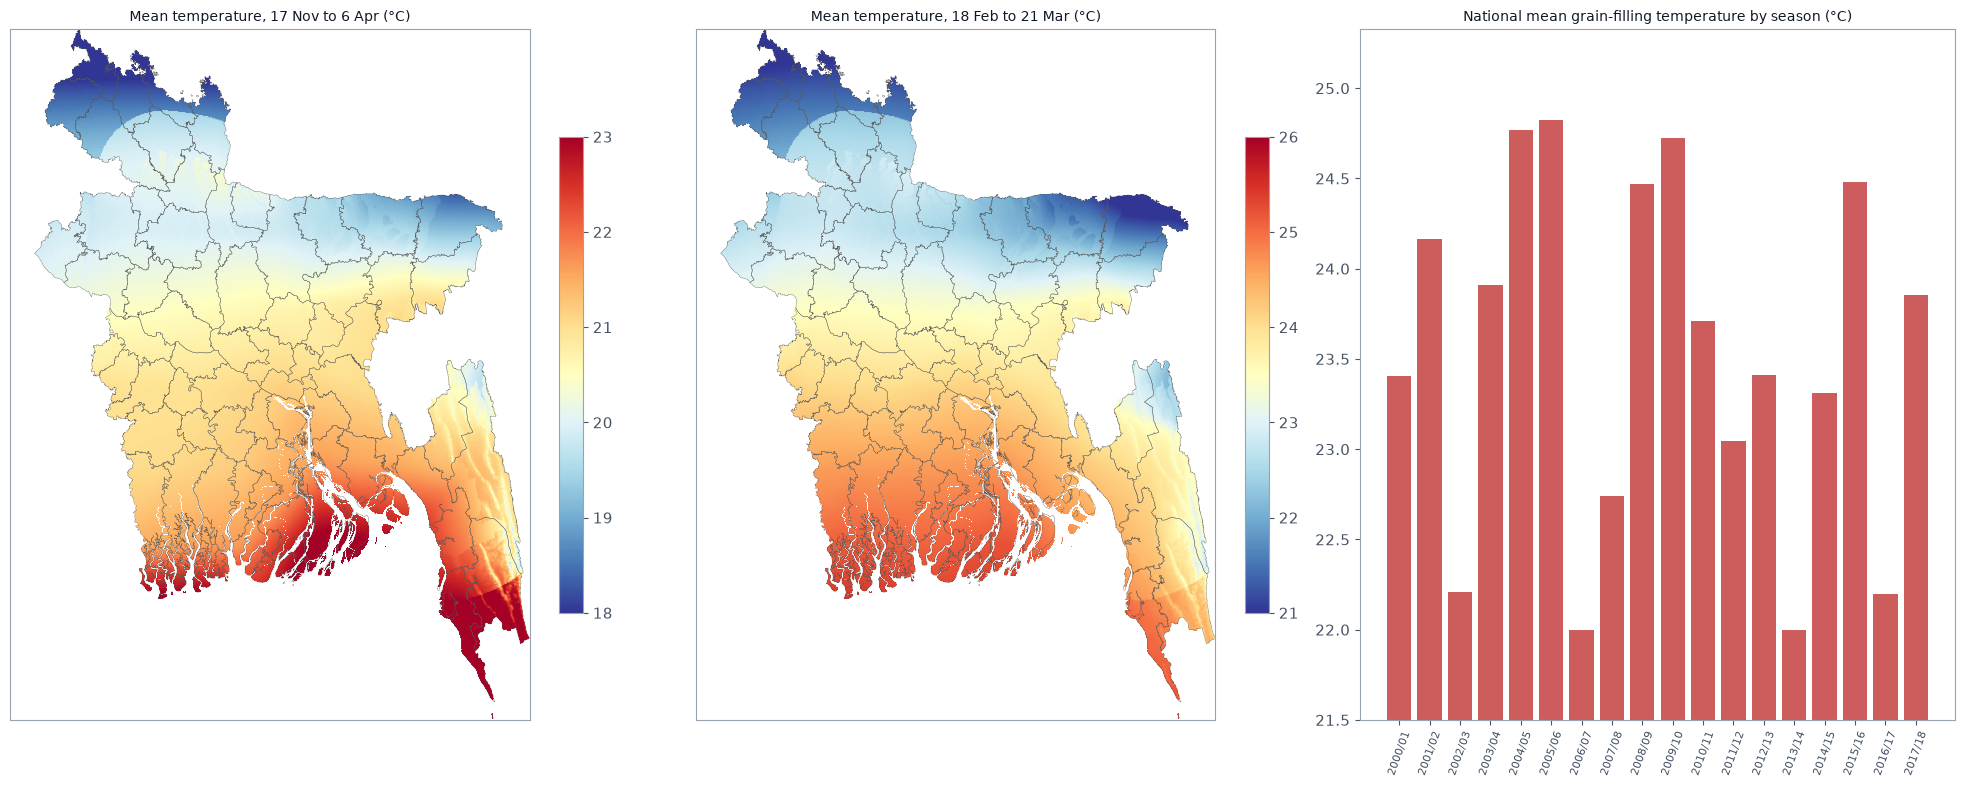

season_T: 18.2 to 23.3 °C (2nd to 98th percentile)
grainfill_T: 21.1 to 25.2 °C (2nd to 98th percentile)


In [6]:
SEASONS = range(2001, 2019)  # harvest years


def composite_files(doys, years=SEASONS):
    files = []
    for y in years:
        for d in doys:
            f = TEMP / "t2m" / f"t2m_{y - 1 if d >= 300 else y}_{d:03d}.tif"
            if f.exists():
                files.append(f)
    return files


def to_mem(arr1km):
    """Wrap a 1 km array as an in-memory GDAL dataset on the temperature grid."""
    mem = gdal.GetDriverByName("MEM").Create("", T_SHAPE[1], T_SHAPE[0], 1, gdal.GDT_Float32)
    mem.SetGeoTransform(T_GT)
    mem.SetProjection(T_WKT)
    band = mem.GetRasterBand(1)
    band.WriteArray(np.where(np.isfinite(arr1km), arr1km, dp.NODATA))
    band.SetNoDataValue(dp.NODATA)
    return mem


def climate_mean(doys, years=SEASONS):
    files = composite_files(doys, years)
    stored = np.mean([gdal.Open(str(f)).ReadAsArray().astype(float) for f in files], axis=0)
    fixed1, _, _ = correct(stored)
    return dp.warp_to_grid(to_mem(fixed1), GRID, resample="bilinear"), len(files)


t0 = time.time()
CLIM = {}
CLIM["season_T"], n_season = climate_mean([321, 337, 353, 1, 17, 33, 49, 65, 81])
CLIM["grainfill_T"], n_gf = climate_mean([49, 65])
print(f"Composites used: season {n_season}, grain filling {n_gf}; {time.time() - t0:.0f} s")

# Year-by-year grain-filling temperature, for the heat-risk map in Section 14.
GF_YEARS = []
for y in SEASONS:
    files = composite_files([49, 65], [y])
    stored = np.mean([gdal.Open(str(f)).ReadAsArray().astype(float) for f in files], axis=0)
    GF_YEARS.append(correct(stored)[0])
GF_YEARS = np.stack(GF_YEARS)

fig, axes = plt.subplots(1, 3, figsize=(20, 8))
im = show(axes[0], CLIM["season_T"], "Mean temperature, 17 Nov to 6 Apr (°C)", "RdYlBu_r", 18, 23)
plt.colorbar(im, ax=axes[0], fraction=0.04)
im = show(axes[1], CLIM["grainfill_T"], "Mean temperature, 18 Feb to 21 Mar (°C)", "RdYlBu_r", 21, 26)
plt.colorbar(im, ax=axes[1], fraction=0.04)
nat = np.nanmean(np.where(LAND1, GF_YEARS, np.nan), axis=(1, 2))
axes[2].bar([f"{y - 1}/{str(y)[2:]}" for y in SEASONS], nat, color="indianred")
axes[2].set_ylim(nat.min() - 0.5, nat.max() + 0.5)
axes[2].set_title("National mean grain-filling temperature by season (°C)", fontsize=10)
axes[2].tick_params(axis="x", rotation=70, labelsize=8)
plt.tight_layout()
plt.show()
for k, v in CLIM.items():
    print(f"{k}: {np.nanpercentile(v[LAND], 2):.1f} to {np.nanpercentile(v[LAND], 98):.1f} °C (2nd to 98th percentile)")

During grain filling the north-west is 3 to 4 °C cooler than the south-western and central coast. The national mean also varies from season to season: the hottest season of the record (2005/06) was about 1.4 °C above the average, enough to move a district a good part of the way from northern to southern conditions.

## Land, soil and water criteria

### Land type and drainage

The soil-survey **land type** classifies land by its normal depth of seasonal flooding. Highland and medium highland are above normal flood level or drain by October; lowland and very lowland stay wet into the dry season, too late for wheat. **Drainage class** describes how fast the soil dries after rain or irrigation; poorly drained soils waterlog at sowing.

### Soil pH and organic carbon

Both are continuous national maps. Wheat does best at pH 6.0 to 7.5; the acid terrace soils of the Madhupur and Barind tracts and the hill soils fall below 5.5. Organic carbon is a proxy for soil fertility and structure.

### Water: groundwater and drought

Irrigation in the dry season comes mostly from groundwater. The **depth to the water table** from February to April 2020 (the irrigation period) is the criterion. Shallow tubewells stop working below about 7 to 8 m, but wheat needs far less water than boro rice and the Barind Tract irrigates it from deep tubewells, so the membership only falls off past about 12 m. The **drought class** describes how prone the land is to moisture stress; it is weighted low because irrigated wheat is drought tolerant compared with transplanted rice.

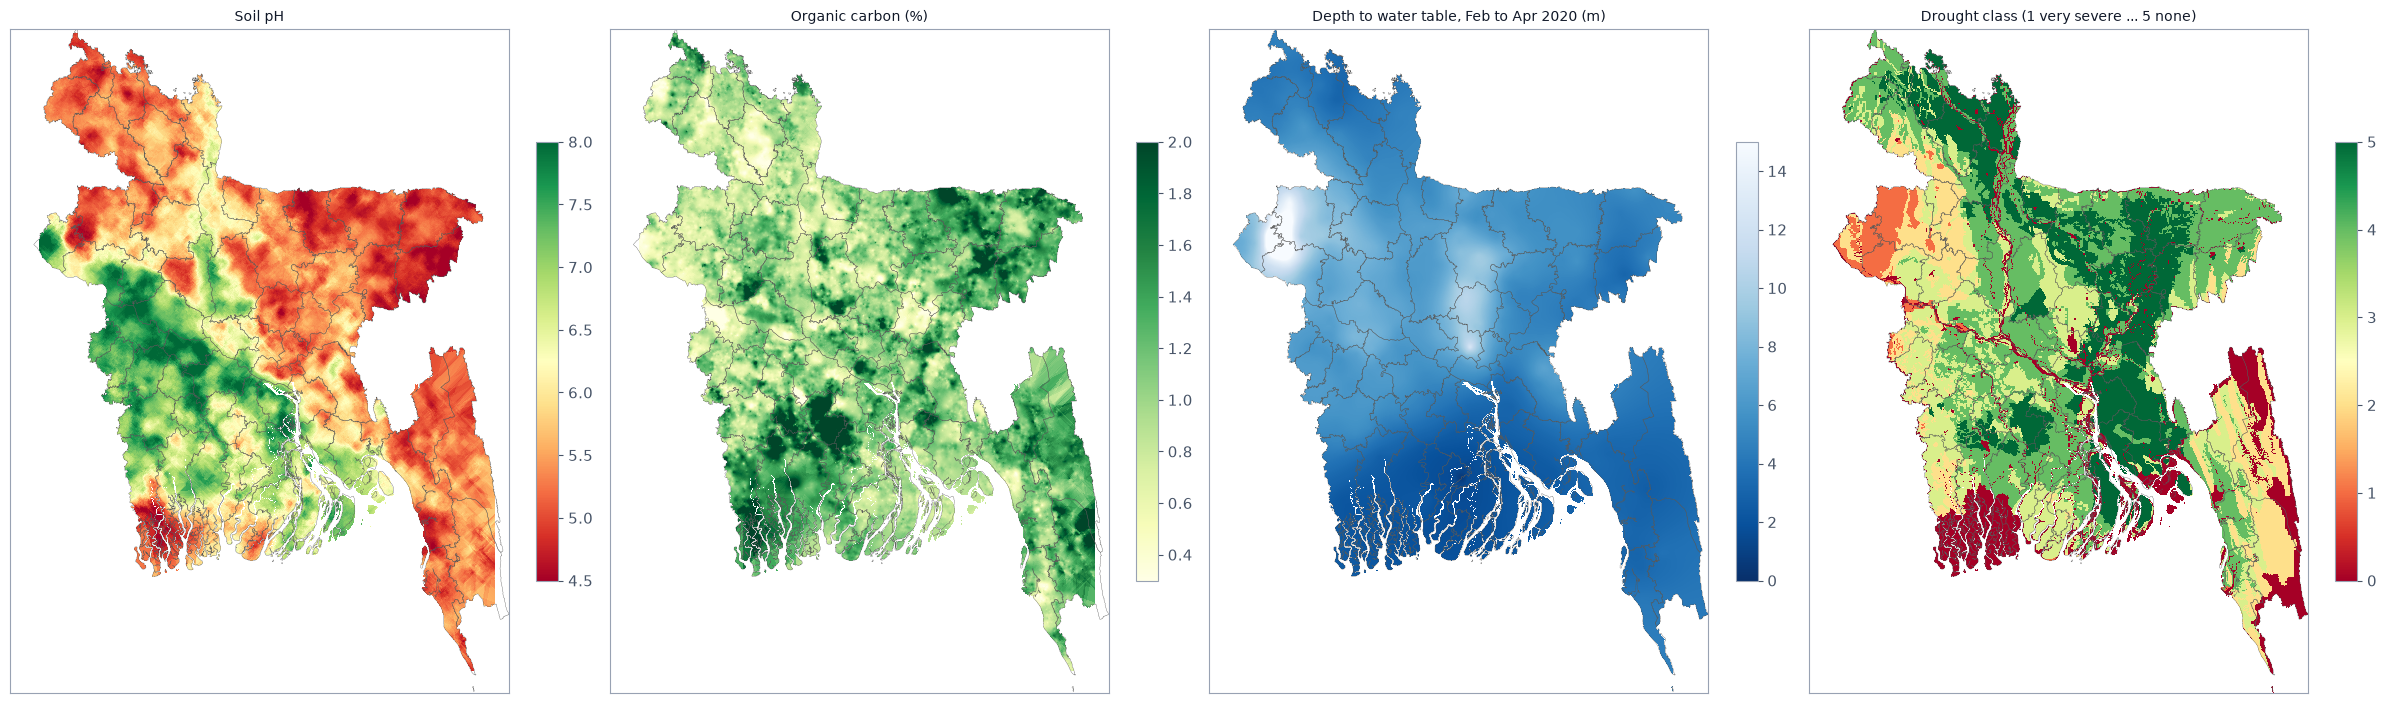

In [7]:
wt = []
for d in (33, 49, 65, 81, 97):  # 2 February to 21 April
    a = dp.warp_to_grid(SRC / "Watertable_2020" / f"watertable_2020_{d:03d}.tif", GRID, resample="bilinear",
                        src_srs=T_WKT)
    a[a < -100] = np.nan
    wt.append(a)
WATER_TABLE = np.nanmean(wt, axis=0)

slope(SRC / "DEM.tif", OUT / "slope_deg.tif", overwrite=True, compute_edges=True)
SLOPE = dp.read_band(OUT / "slope_deg.tif")[0]

fig, axes = plt.subplots(1, 4, figsize=(24, 8))
for ax, arr, title, cmap, lims in zip(
        axes, (LAYERS["pH"], LAYERS["OC"], WATER_TABLE, LAYERS["DROUGHT"]),
        ("Soil pH", "Organic carbon (%)", "Depth to water table, Feb to Apr 2020 (m)", "Drought class (1 very severe ... 5 none)"),
        ("RdYlGn", "YlGn", "Blues_r", "RdYlGn"), ((4.5, 8), (0.3, 2), (0, 15), (0, 5))):
    im = show(ax, arr, title, cmap, *lims)
    plt.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout()
plt.show()

## Constraints

Constraints are Boolean: a cell either passes all of them or is classed **N2** (permanently unsuitable) whatever its scores.

| Constraint | Rule |
|---|---|
| Not farmland | general soil type 0: water bodies, urban, reserved forest, Sundarbans, Kaptai Lake |
| Problem soils | acid sulphate soils and peat |
| Hills | AEZ 29 (Northern and Eastern Hills), or slope above 5° |
| Very lowland | land type 6: under deep water until late in the dry season |
| Missing data | land type or drainage class not mapped |

In [8]:
CONSTRAINTS = {
    "farmland": ~np.isin(LAYERS["STYPE"], [0]),
    "no problem soils": ~np.isin(LAYERS["STYPE"], [11, 12]),
    "not hills": ~np.isin(LAYERS["AEZ"], [29]) & (np.nan_to_num(SLOPE) <= 5),
    "not very lowland": LAYERS["LT"] != 6,
    "mapped": np.isin(LAYERS["LT"], [1, 2, 3, 4, 5]) & np.isfinite(LAYERS["DRC"]) & (LAYERS["DRC"] > 0),
}
OK = categorical_and([LAND & c for c in CONSTRAINTS.values()])
rows = [(k, np.mean(~c[LAND]) * 100) for k, c in CONSTRAINTS.items()]
display(pd.DataFrame(rows, columns=["constraint", "% of land failing"]).set_index("constraint").round(1))
print(f"Land passing all constraints: {OK.sum() * 0.0625:,.0f} km² ({OK.sum() / LAND.sum():.0%} of land)")

,% of land failing
constraint,
farmland,12.4
no problem soils,1.3
not hills,11.2
not very lowland,1.5
mapped,16.7


Land passing all constraints: 103,088 km² (73% of land)


## Fuzzy memberships

Each criterion becomes a membership between 0 (not suitable) and 1 (fully suitable). Continuous criteria use the GeoLattice membership functions; class layers use score tables.

| Criterion | Function | Parameters | Reasoning |
|---|---|---|---|
| `grainfill_T` | `linear`, decreasing | 1 at 21 °C, 0 at 27 °C | each degree of warming during grain filling reduces yield |
| `season_T` | `trapezoidal_mf` | 0 at 13, 1 from 15 to 20, 0 at 26 °C | a cool, long season gives time for tillering |
| `land_type` | scores | highland and medium highland 1 = 1.0, medium highland 2 = 0.75, medium lowland = 0.35, lowland = 0.1 | land must be free of water by mid-November |
| `drainage` | scores | well and moderately well drained = 1.0 ... very poorly drained = 0.1 | waterlogging at sowing and tillering |
| `irrigation` | `small` | midpoint 12 m, spread 4 | groundwater must be within reach of tubewells |
| `pH` | `trapezoidal_mf` | 0 at 4.5, 1 from 5.8 to 7.5, 0 at 8.5 | acidity and alkalinity limit nutrients |
| `OC` | `linear` | 0 at 0.5 %, 1 at 1.5 % | fertility and soil structure |
| `drought` | scores | very severe 0.6 ... none 1.0 | moisture stress between irrigations |

,drainage class,score
16,Very Poorly Drained,0.10
7,Mixed Poorly Drained & Very Poorly Drained,0.15
13,Mostly Very Poorly Drained,0.15
15,Poorly Drained,0.30
12,Mostly Poorly Drained,0.35
3,Mixed Imperfectly Drained & Poorly Drained,0.50
5,Mixed Moderately Well Drained & Poorly Drained,0.60
9,Mixed Well Drained & Poorly Drained,0.60
1,Imperfectly Drained,0.70
4,Mixed Imperfectly Drained & Well Drained,0.85


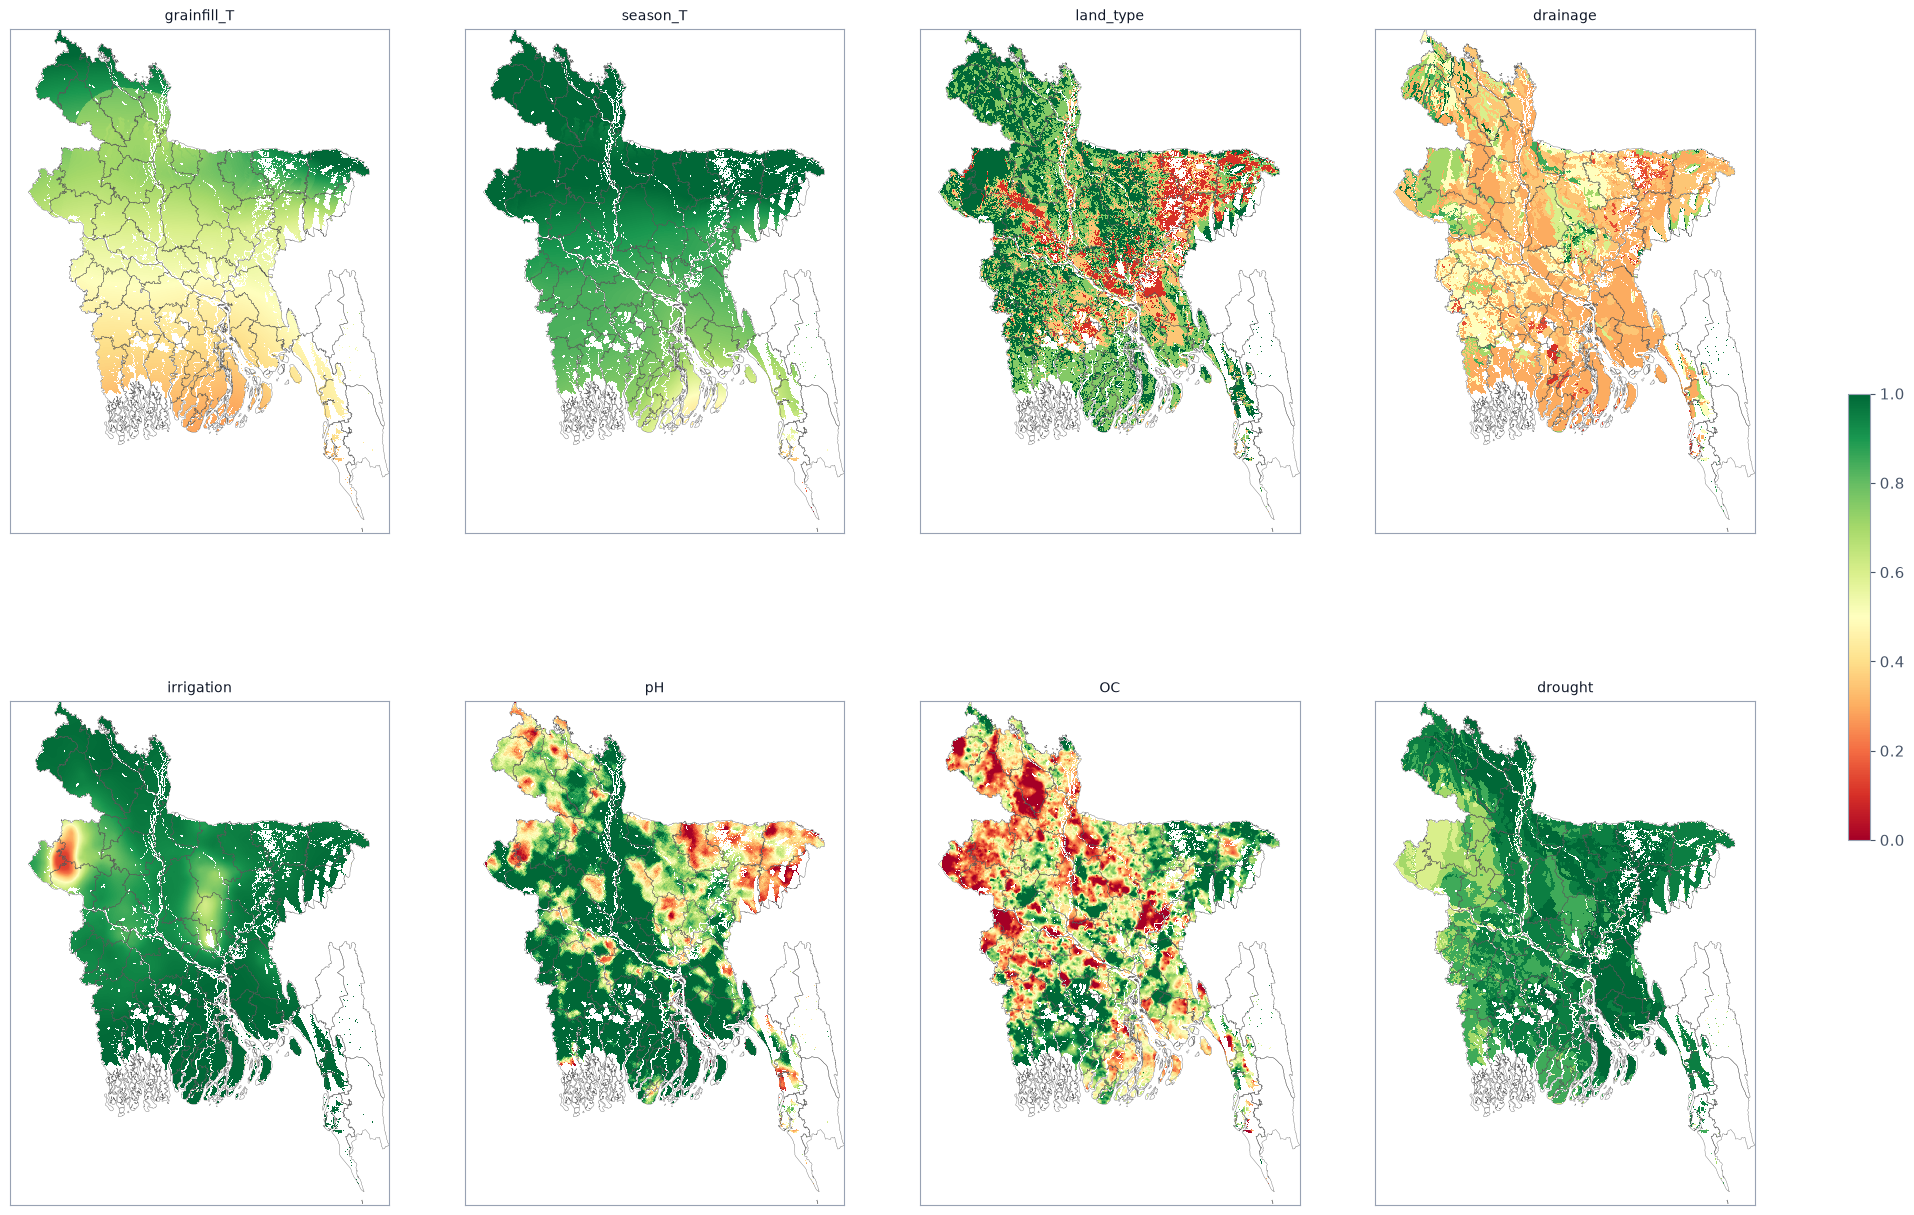

,mean,10%,50%,90%
grainfill_T,0.61,0.38,0.60,0.87
season_T,0.89,0.75,0.91,1.00
land_type,0.70,0.10,0.75,1.00
drainage,0.41,0.30,0.35,0.70
irrigation,0.92,0.81,0.96,1.00
pH,0.76,0.34,0.87,1.00
OC,0.53,0.12,0.52,1.00
drought,0.90,0.70,0.95,1.00


In [9]:
LT_SCORE = {1: 1.0, 2: 1.0, 3: 0.75, 4: 0.35, 5: 0.1, 6: 0.0}
DRC_SCORE = {1: 0.7, 2: 0.85, 3: 0.5, 4: 0.85, 5: 0.6, 6: 1.0, 7: 0.15, 8: 1.0, 9: 0.6, 10: 1.0, 11: 0.95,
             12: 0.35, 13: 0.15, 14: 0.95, 15: 0.3, 16: 0.1, 17: 1.0}
DROUGHT_SCORE = {1: 0.6, 2: 0.7, 3: 0.85, 4: 0.95, 5: 1.0}
display(pd.DataFrame({"drainage class": DRC_NAMES, "score": DRC_SCORE}).dropna().sort_values("score"))


def score(arr, table):
    return pd.Series(arr.ravel()).map(table).values.reshape(arr.shape).astype(float)


def memberships(irrigation_midpoint=12.0, drought_table=DROUGHT_SCORE):
    m = {
        "grainfill_T": linear(CLIM["grainfill_T"], 27.0, 21.0),
        "season_T": trapezoidal_mf(CLIM["season_T"], (13.0, 15.0, 20.0, 26.0)),
        "land_type": score(LAYERS["LT"], LT_SCORE),
        "drainage": score(LAYERS["DRC"], DRC_SCORE),
        "irrigation": small(np.maximum(WATER_TABLE, 0.01), irrigation_midpoint, 4.0),
        "pH": trapezoidal_mf(LAYERS["pH"], (4.5, 5.8, 7.5, 8.5)),
        "OC": linear(LAYERS["OC"], 0.5, 1.5),
        "drought": score(LAYERS["DROUGHT"], drought_table),
    }
    # Clip to [0, 1]; a missing value inside the farmland mask gets a neutral 0.5.
    return {k: np.where(OK, np.clip(np.nan_to_num(np.asarray(v, float), nan=0.5), 0, 1), np.nan)
            for k, v in m.items()}


MEMBERS = memberships()
CRITERIA = list(MEMBERS)
fig, axes = plt.subplots(2, 4, figsize=(24, 16))
for ax, k in zip(axes.ravel(), CRITERIA):
    im = show(ax, MEMBERS[k], k, "RdYlGn", 0, 1)
plt.colorbar(im, ax=axes, fraction=0.012)
plt.show()
display(pd.DataFrame({k: pd.Series(v[OK]).describe(percentiles=[0.1, 0.5, 0.9]) for k, v in MEMBERS.items()})
        .T[["mean", "10%", "50%", "90%"]].round(2))

## AHP weights

The pairwise judgments put **grain-filling heat** and **land type** first: they decide whether wheat can be sown in time and whether it can fill its grain. Drainage and irrigation follow; soil chemistry, season temperature and drought are secondary.

In [10]:
JUDGMENTS = {
    ("grainfill_T", "season_T"): 3, ("grainfill_T", "land_type"): 1, ("grainfill_T", "drainage"): 2,
    ("grainfill_T", "irrigation"): 2, ("grainfill_T", "pH"): 3, ("grainfill_T", "OC"): 5, ("grainfill_T", "drought"): 4,
    ("season_T", "land_type"): 1 / 3, ("season_T", "drainage"): 1 / 2, ("season_T", "irrigation"): 1 / 2,
    ("season_T", "pH"): 1, ("season_T", "OC"): 2, ("season_T", "drought"): 2,
    ("land_type", "drainage"): 2, ("land_type", "irrigation"): 2, ("land_type", "pH"): 3, ("land_type", "OC"): 5,
    ("land_type", "drought"): 4,
    ("drainage", "irrigation"): 1, ("drainage", "pH"): 2, ("drainage", "OC"): 3, ("drainage", "drought"): 3,
    ("irrigation", "pH"): 2, ("irrigation", "OC"): 3, ("irrigation", "drought"): 2,
    ("pH", "OC"): 2, ("pH", "drought"): 1,
    ("OC", "drought"): 1 / 2,
}
RANDOM_INDEX = {1: 0.0, 2: 0.0, 3: 0.58, 4: 0.90, 5: 1.12, 6: 1.24, 7: 1.32, 8: 1.41, 9: 1.45, 10: 1.49}


def ahp(criteria, judgments):
    """AHP weights (principal eigenvector) and consistency ratio for a reciprocal matrix."""
    n = len(criteria)
    A = np.ones((n, n))
    for (a, b), v in judgments.items():
        i, j = criteria.index(a), criteria.index(b)
        A[i, j], A[j, i] = v, 1.0 / v
    vals, vecs = np.linalg.eig(A)
    k = np.argmax(vals.real)
    w = np.abs(vecs[:, k].real)
    w = w / w.sum()
    ci = (vals[k].real - n) / (n - 1)
    return pd.Series(w, index=criteria), A, ci / RANDOM_INDEX[n]


W_AHP, A_MATRIX, CR = ahp(CRITERIA, JUDGMENTS)
display(pd.DataFrame(A_MATRIX, index=CRITERIA, columns=CRITERIA).round(2))
display(W_AHP.rename("weight").to_frame().T.round(3))
print(f"Consistency ratio: {CR:.3f} ({'acceptable' if CR < 0.10 else 'revise the judgments'})")

,grainfill_T,season_T,land_type,drainage,irrigation,pH,OC,drought
grainfill_T,1.00,3.0,1.00,2.00,2.00,3.0,5.0,4.0
season_T,0.33,1.0,0.33,0.50,0.50,1.0,2.0,2.0
land_type,1.00,3.0,1.00,2.00,2.00,3.0,5.0,4.0
drainage,0.50,2.0,0.50,1.00,1.00,2.0,3.0,3.0
irrigation,0.50,2.0,0.50,1.00,1.00,2.0,3.0,2.0
pH,0.33,1.0,0.33,0.50,0.50,1.0,2.0,1.0
OC,0.20,0.5,0.20,0.33,0.33,0.5,1.0,0.5
drought,0.25,0.5,0.25,0.33,0.50,1.0,2.0,1.0


,grainfill_T,season_T,land_type,drainage,irrigation,pH,OC,drought
weight,0.238,0.08,0.238,0.138,0.131,0.073,0.041,0.06


Consistency ratio: 0.008 (acceptable)


## Combining the criteria

Three rules, from fully compensatory to not compensatory at all:

- **Weighted linear combination (WLC)**: a weighted mean. A poor score on one criterion can be offset by good scores on others.
- **Weighted fuzzy gamma** (γ = 0.8): between the fuzzy product (all criteria must be good) and the fuzzy sum. Low scores pull the result down more than in WLC.
- **Limiting factor** (minimum): the cell is only as suitable as its worst criterion, following Liebig's law of the minimum and the FAO practice of classing land by its most severe limitation.

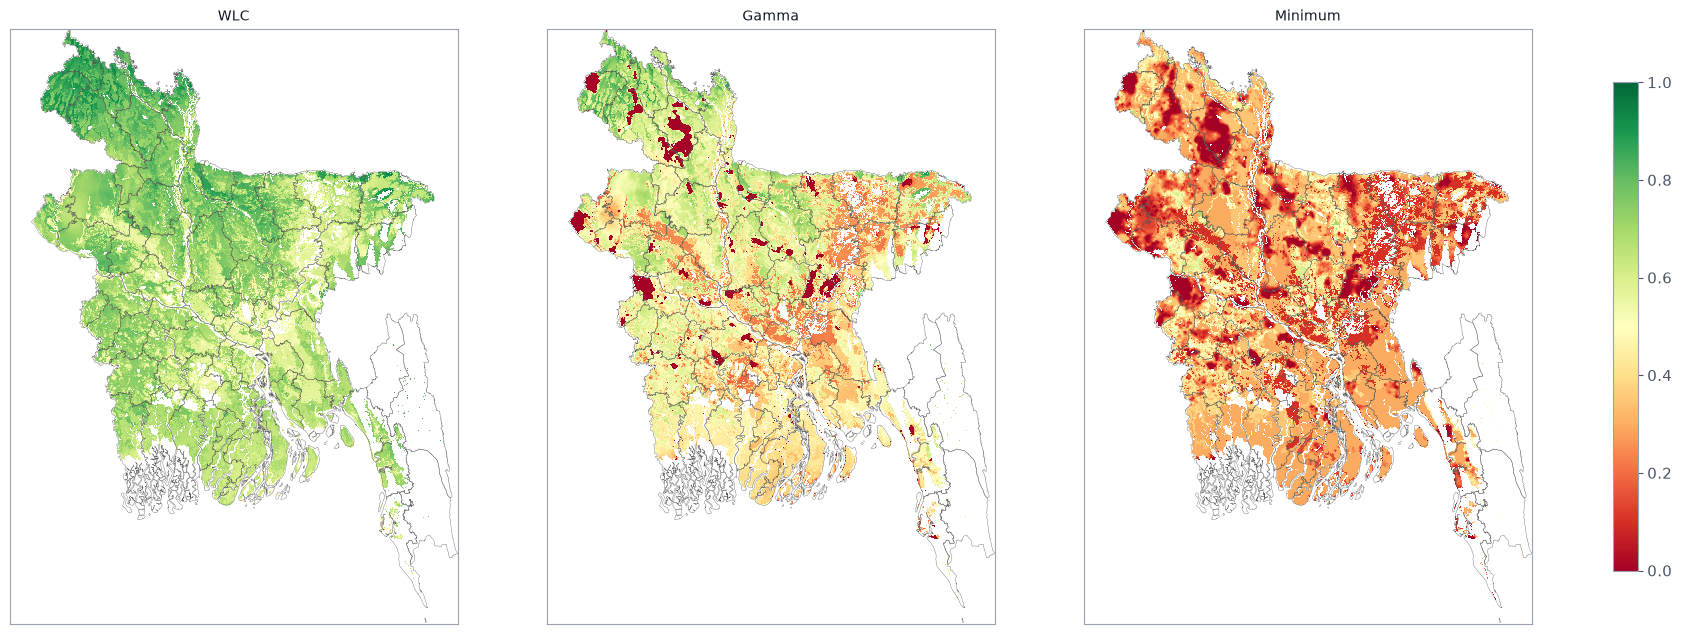

,mean,10%,50%,90%
WLC,0.691,0.567,0.694,0.808
Gamma,0.459,0.235,0.478,0.649
Minimum,0.262,0.100,0.300,0.405


In [11]:
def combine(members, weights):
    stack = [members[k] for k in CRITERIA]
    out = {
        "WLC": weighted_linear_combination(members, weights.to_dict()),
        "Gamma": weighted_fuzzy_overlay(stack, weights.values, gamma=0.8),
        "Minimum": np.min(np.stack(stack), axis=0),
    }
    return {k: np.where(OK, v, np.nan) for k, v in out.items()}


SCORES = combine(MEMBERS, W_AHP)
fig, axes = plt.subplots(1, 3, figsize=(21, 9))
for ax, (k, v) in zip(axes, SCORES.items()):
    im = show(ax, v, k, "RdYlGn", 0, 1)
plt.colorbar(im, ax=axes, fraction=0.015)
plt.show()
display(pd.DataFrame({k: pd.Series(v[OK]).describe(percentiles=[0.1, 0.5, 0.9]) for k, v in SCORES.items()})
        .T[["mean", "10%", "50%", "90%"]].round(3))

All three rules agree on the pattern: the north-west is the most suitable region, followed by the High Ganges and Old Brahmaputra floodplains, while the coast, the haors and the hills are poor. They differ in level and contrast. WLC averages away single weaknesses, gamma penalises them, and the minimum is set entirely by the weakest criterion, which for much of the country is drainage or land type.

## FAO suitability classes

The FAO framework uses five classes. Here they are cut from the **WLC** score, the headline model:

| Class | Meaning | WLC score |
|---|---|---|
| S1 | highly suitable | at least 0.80 |
| S2 | moderately suitable | 0.70 to 0.80 |
| S3 | marginally suitable | 0.60 to 0.70 |
| N1 | currently not suitable | below 0.60 |
| N2 | permanently not suitable | fails a constraint |

The break points are a choice: they are set so that S1 picks out land with no serious limitation, and their effect is tested in Section 14.

,km²,% of land
N2,38382.0,27.0
N1,20209.0,14.0
S3,33256.0,24.0
S2,37519.0,27.0
S1,12104.0,9.0


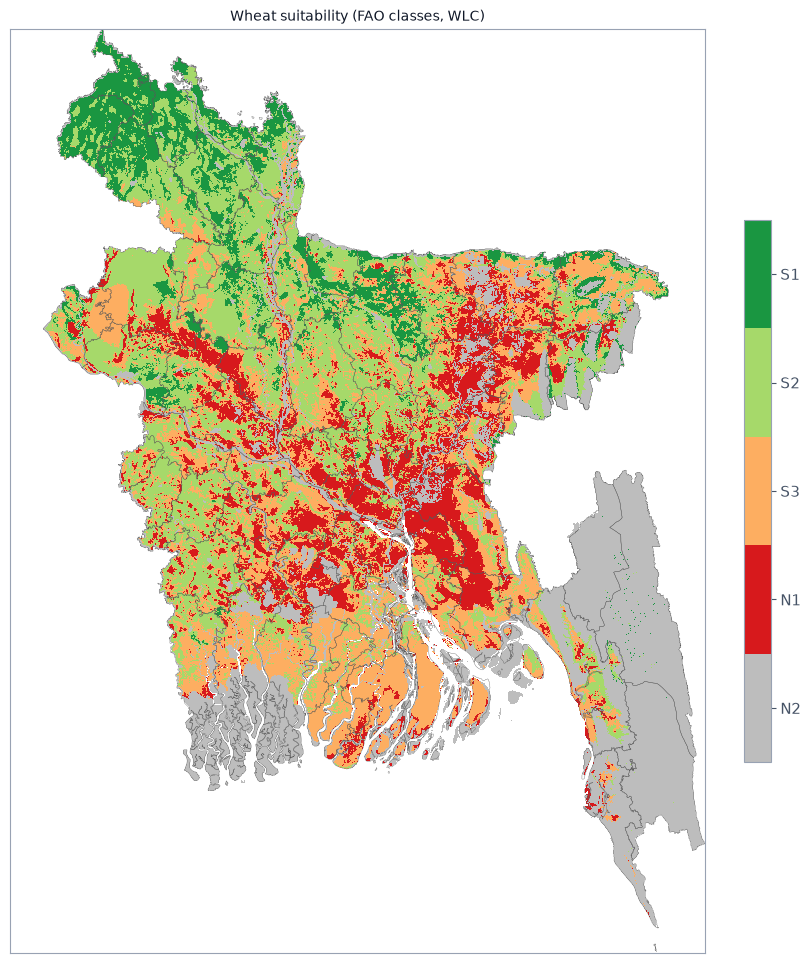

In [12]:
CLASS_NAMES = ["N2", "N1", "S3", "S2", "S1"]
CLASS_CMAP = ListedColormap(["#bdbdbd", "#d7191c", "#fdae61", "#a6d96a", "#1a9641"])
BREAKS = (0.60, 0.70, 0.80)


def fao_classes(score_, breaks=BREAKS):
    c = np.full(GRID.shape, np.nan)
    c[LAND] = 0  # N2
    s = np.where(OK, score_, np.nan)
    c[OK] = 1 + np.digitize(s[OK], breaks)  # 1 = N1, 2 = S3, 3 = S2, 4 = S1
    return c


CLS = fao_classes(SCORES["WLC"])
area = pd.Series({n: np.sum(CLS == i) * 0.0625 for i, n in enumerate(CLASS_NAMES)}, name="km²").to_frame()
area["% of land"] = area["km²"] / area["km²"].sum() * 100
display(area.round(0))

fig, ax = plt.subplots(figsize=(10, 12))
im = show(ax, CLS, "Wheat suitability (FAO classes, WLC)", CLASS_CMAP, -0.5, 4.5)
cb = plt.colorbar(im, ax=ax, fraction=0.035, ticks=range(5))
cb.ax.set_yticklabels(CLASS_NAMES)
plt.show()

## What limits wheat where

`limiting_criterion` returns the criterion with the lowest membership in each cell: the first thing to fix, or the reason land is not better. `score_contributions` splits the WLC score into its weighted parts.

% of class area where the criterion is the weakest,N1,S3,S2,S1
grainfill_T,0.6,3.5,7.9,2.3
season_T,0.0,0.0,0.0,0.0
land_type,56.2,13.3,0.2,0.0
drainage,27.4,53.8,37.7,22.0
irrigation,0.0,0.9,0.5,0.0
pH,3.4,7.4,11.3,22.1
OC,12.3,21.1,42.4,53.3
drought,0.0,0.0,0.1,0.1


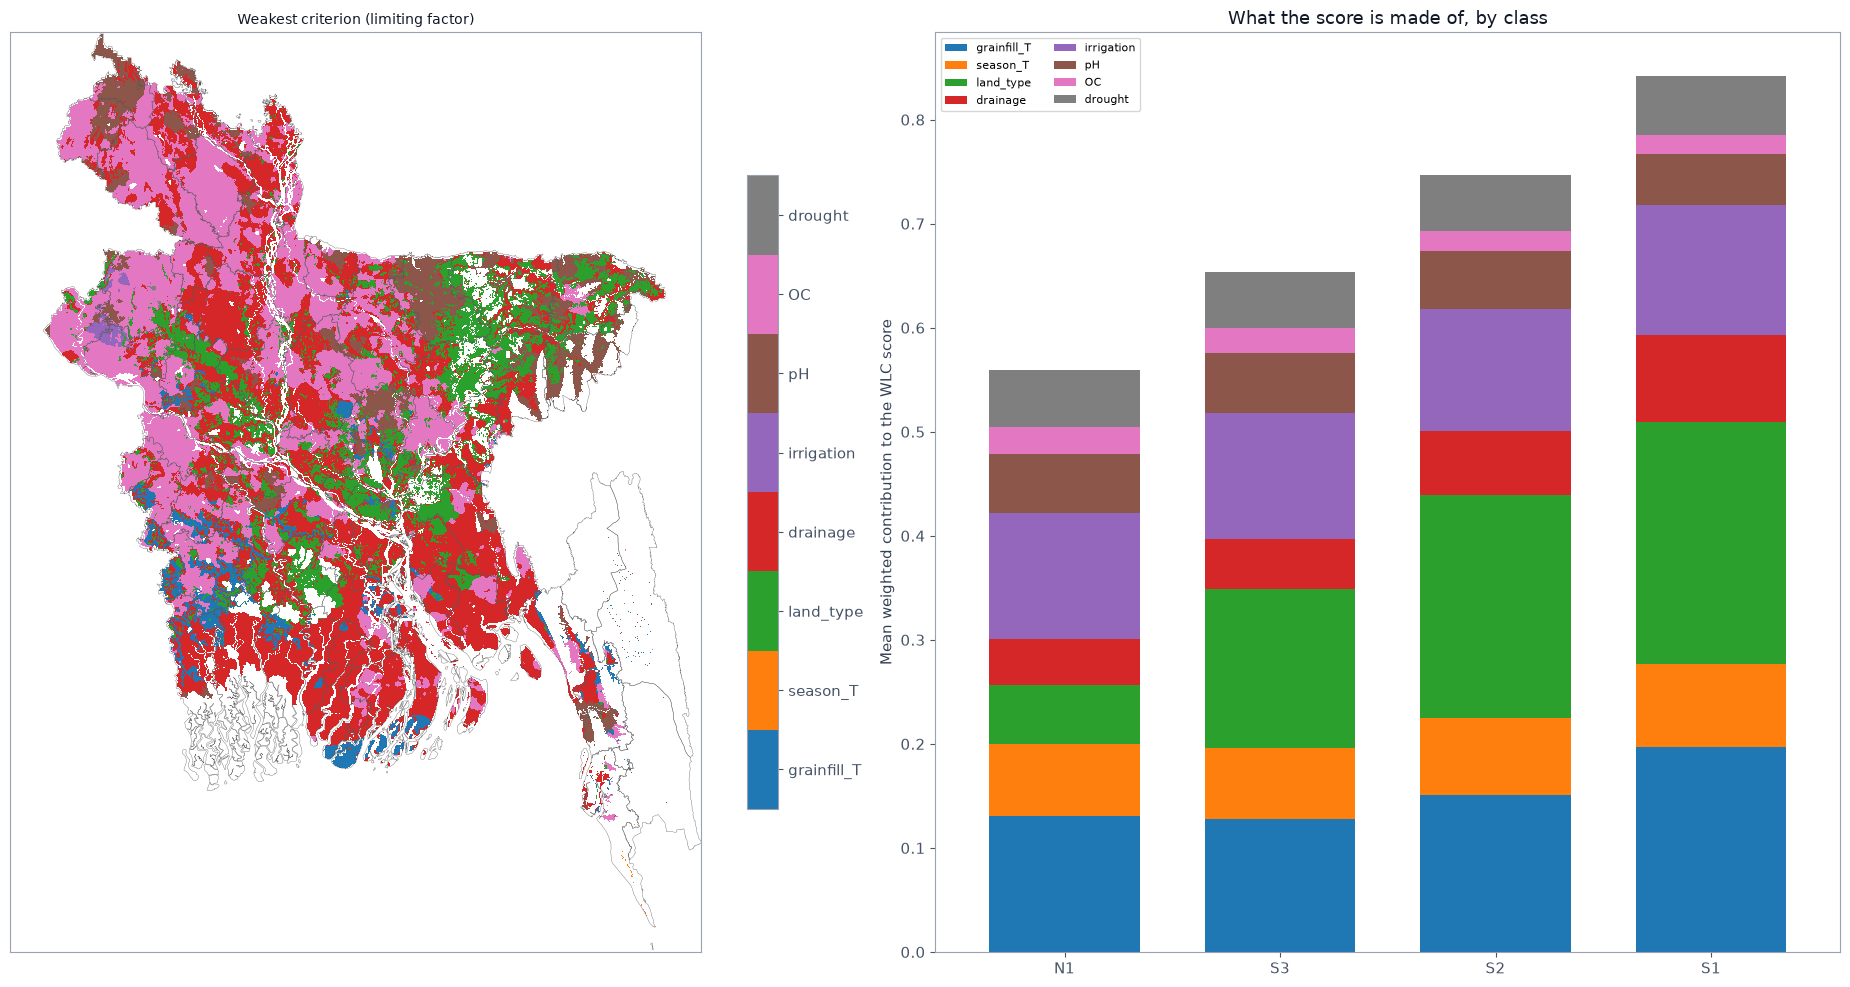

In [13]:
lim = limiting_criterion({k: np.where(OK, MEMBERS[k], np.inf) for k in CRITERIA})
LIMIT = np.full(GRID.shape, np.nan)
for i, k in enumerate(CRITERIA):
    LIMIT[(lim == k) & OK] = i
lim_tab = pd.DataFrame({
    cname: [np.mean(LIMIT[CLS == ci] == i) * 100 for i in range(len(CRITERIA))]
    for ci, cname in enumerate(CLASS_NAMES) if ci > 0
}, index=CRITERIA)
display(lim_tab.round(1).rename_axis(columns="% of class area where the criterion is the weakest"))

contrib = score_contributions({k: MEMBERS[k] for k in CRITERIA}, W_AHP.to_dict())
contrib_tab = pd.DataFrame({cname: [np.nanmean(contrib[k][CLS == ci]) for k in CRITERIA]
                            for ci, cname in enumerate(CLASS_NAMES) if ci > 0}, index=CRITERIA)

fig, axes = plt.subplots(1, 2, figsize=(20, 10), gridspec_kw={"width_ratios": [1, 1]})
cmap_lim = ListedColormap(plt.cm.tab10.colors[:len(CRITERIA)])
im = show(axes[0], LIMIT, "Weakest criterion (limiting factor)", cmap_lim, -0.5, len(CRITERIA) - 0.5)
cb = plt.colorbar(im, ax=axes[0], fraction=0.035, ticks=range(len(CRITERIA)))
cb.ax.set_yticklabels(CRITERIA)
contrib_tab.T.plot.bar(stacked=True, ax=axes[1], color=plt.cm.tab10.colors[:len(CRITERIA)], width=0.7)
axes[1].set_ylabel("Mean weighted contribution to the WLC score")
axes[1].set_title("What the score is made of, by class")
axes[1].legend(fontsize=8, ncol=2)
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

**Reading the limiting factors.** In N1 land the weakest criterion is mostly **land type** (lowland that is still wet at sowing), followed by drainage. In S3 land it is mostly **drainage**: the national soil map classes much of the floodplain as poorly drained. In S2 and S1 land the weak points are **organic carbon** and **pH**, criteria that liming, manure and residue management can improve. Grain-filling heat is rarely the single weakest criterion, because its membership falls gradually; its effect shows in the weighted score and in the hot-season test of Section 14.

## Validation against the wheat districts

The 14 districts named in Section 2 grow about 90 % of the country's wheat. If the map is right, they should rank high. Two measures per district:

- the mean WLC score of land passing the constraints (only for districts where at least a quarter of the land passes them; otherwise a few valley cells in the hill districts would stand for the whole district);
- the share of land that is S1 or S2.

The **AUC** is the probability that a randomly chosen wheat district scores higher than a randomly chosen other district (0.5 = no better than chance). Because farmers' choices also depend on markets and on competing crops, a perfect score is not expected.

The model is also run with the **strict water criteria** an analyst might start from: irrigation falling off past 7 m (shallow-tubewell depth) and drought scored 0.2 for very severe to 1.0 for none.

,AUC (mean score),AUC (S1+S2 share),wheat districts among top 14
model,,,
WLC (headline),0.674,0.704,4
Gamma,0.595,0.697,4
Minimum,0.430,0.722,2
"WLC, strict water criteria",0.531,0.563,4


Districts ranked: 60 of 64; not ranked (less than 25% farmland): Bandarban, Cox's Bazar, Khagrachhari, Rangamati


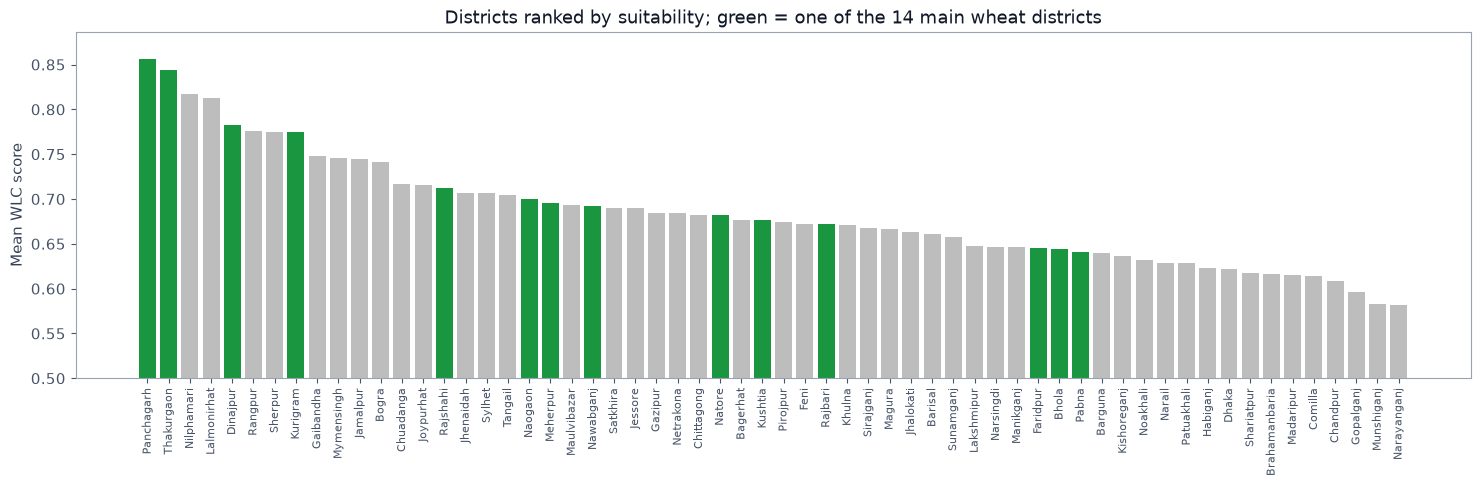

In [14]:
MAJOR = ["Thakurgaon", "Nawabganj", "Natore", "Rajshahi", "Pabna", "Faridpur", "Naogaon", "Panchagarh", "Meherpur",
         "Kushtia", "Rajbari", "Bhola", "Kurigram", "Dinajpur"]  # Nawabganj = Chapainawabganj in the boundary file


MIN_FARMLAND = 0.25  # districts with less land passing the constraints are not ranked on the mean score


def district_table(score_, cls):
    rows = []
    for i, name in enumerate(dist.ADM2_EN, start=1):
        m = (DIST_ID == i) & LAND
        ok = m & OK
        share_ok = ok.sum() / max(m.sum(), 1)
        rows.append((name, np.nanmean(score_[ok]) if share_ok >= MIN_FARMLAND else np.nan,
                     np.mean(cls[m] >= 3) * 100, share_ok * 100, name in MAJOR))
    return pd.DataFrame(rows, columns=["district", "mean_score", "S1_S2_pct", "farmland_pct", "major_wheat"]) \
        .set_index("district")


strict = memberships(irrigation_midpoint=7.0, drought_table={1: 0.2, 2: 0.4, 3: 0.7, 4: 0.9, 5: 1.0})
strict_wlc = combine(strict, W_AHP)["WLC"]
RUNS = {"WLC (headline)": (SCORES["WLC"], CLS), "Gamma": (SCORES["Gamma"], fao_classes(SCORES["Gamma"], (0.4, 0.5, 0.6))),
        "Minimum": (SCORES["Minimum"], fao_classes(SCORES["Minimum"], (0.3, 0.4, 0.5))),
        "WLC, strict water criteria": (strict_wlc, fao_classes(strict_wlc))}
rows = []
for name, (s, c) in RUNS.items():
    t = district_table(s, c)
    tr_ = t.dropna(subset=["mean_score"])
    top14 = tr_.mean_score.nlargest(14).index
    rows.append((name, roc_auc_score(tr_.major_wheat, tr_.mean_score), roc_auc_score(t.major_wheat, t.S1_S2_pct),
                 int(np.sum(t.loc[top14, "major_wheat"]))))
display(pd.DataFrame(rows, columns=["model", "AUC (mean score)", "AUC (S1+S2 share)", "wheat districts among top 14"])
        .set_index("model").round(3))

DT = district_table(SCORES["WLC"], CLS).dropna(subset=["mean_score"]).sort_values("mean_score", ascending=False)
print(f"Districts ranked: {len(DT)} of {len(dist)}; not ranked (less than {MIN_FARMLAND:.0%} farmland): "
      f"{', '.join(sorted(set(dist.ADM2_EN) - set(DT.index)))}")
fig, ax = plt.subplots(figsize=(18, 4.5))
ax.bar(DT.index, DT.mean_score, color=np.where(DT.major_wheat, "#1a9641", "#bdbdbd"))
ax.set_ylim(0.5, DT.mean_score.max() + 0.03)
ax.set_ylabel("Mean WLC score")
ax.set_title("Districts ranked by suitability; green = one of the 14 main wheat districts")
ax.tick_params(axis="x", rotation=90, labelsize=8)
plt.show()

**Reading the validation.** Agreement is moderate (AUC about 0.67 on the mean score and 0.70 on the S1 + S2 share). The four hill districts (Bandarban, Cox's Bazar, Khagrachhari, Rangamati) are not ranked: less than a quarter of their land passes the constraints. The north-western wheat districts (Thakurgaon, Panchagarh, Dinajpur, Kurigram) are among the highest-ranked districts in the country. The Ganges-floodplain wheat districts (Rajshahi, Natore, Naogaon, Pabna, Kushtia, Meherpur, Faridpur, Rajbari) sit in the middle: warmer during grain filling, with deep water tables in the Barind and much poorly drained land. Several high-ranking districts that are not on the list lie in the same cool north (Nilphamari, Lalmonirhat, Rangpur, Gaibandha, Bogura) or in the north-centre (Sherpur, Jamalpur, Mymensingh), where potato, maize and boro rice compete for the same land in the same season. Bhola, a coastal island district, is on the list although its grain-filling temperatures are high: the model would need sowing dates and local soil detail to explain it.

The strict water criteria rank the Barind districts much lower and agree clearly less with where wheat is grown (AUC about 0.5, no better than chance), which is why the headline model uses the deep-tubewell setting. The minimum rule ranks the wheat districts worst of all on the mean score: one poor criterion anywhere in a district drags it down.

## Uncertainty

### Weights

`monte_carlo_weights` draws 300 weight vectors from a Dirichlet distribution centred on the AHP weights and records, for every cell, how often it stays in the top 30 % of WLC scores (roughly the S1 and S2 classes).

In [15]:
idx_ok = np.flatnonzero(OK.ravel())
M = np.stack([MEMBERS[k].ravel()[idx_ok] for k in CRITERIA])
t0 = time.time()
mc = monte_carlo_weights(M, W_AHP.values, kappa=50.0, n=300, batch=10, top_q=0.7, seed=3)
P_TOP = np.full(int(np.prod(GRID.shape)), np.nan)
P_TOP[idx_ok] = mc["p_top"]
P_TOP = P_TOP.reshape(GRID.shape)
print(f"Monte Carlo weights in {time.time() - t0:.0f} s; median Jaccard of the top-30 % set vs the AHP baseline: "
      f"{np.median(mc['jaccard']):.2f}")

Monte Carlo weights in 40 s; median Jaccard of the top-30 % set vs the AHP baseline: 0.80


### A hot season

The climate criteria use the 18-season mean. To see how a single season changes the picture, the share of seasons in which the grain-filling mean exceeded **24 °C** is mapped (about 3 °C above the coolest districts). The WLC is also recomputed with the grain-filling temperature of the hottest season in the record.

Hottest grain-filling period: 2005/2006 (national mean 24.8 °C vs 23.5 °C on average)


km²,average season,hottest season
N2,38382.0,38382.0
N1,20209.0,36219.0
S3,33256.0,38478.0
S2,37519.0,22974.0
S1,12104.0,5416.0


Jaccard index of class masks:
  S1+S2, WLC (headline) vs Gamma: 0.83
  S1+S2, WLC (headline) vs Minimum: 0.19
  S1+S2, WLC (headline) vs WLC, strict water criteria: 0.66
  S1+S2, average vs hottest season: 0.57
  S1+S2, breaks (0.6, 0.7, 0.8) vs (0.58, 0.68, 0.78): 0.88
  S1+S2, breaks (0.6, 0.7, 0.8) vs (0.62, 0.72, 0.82): 0.85


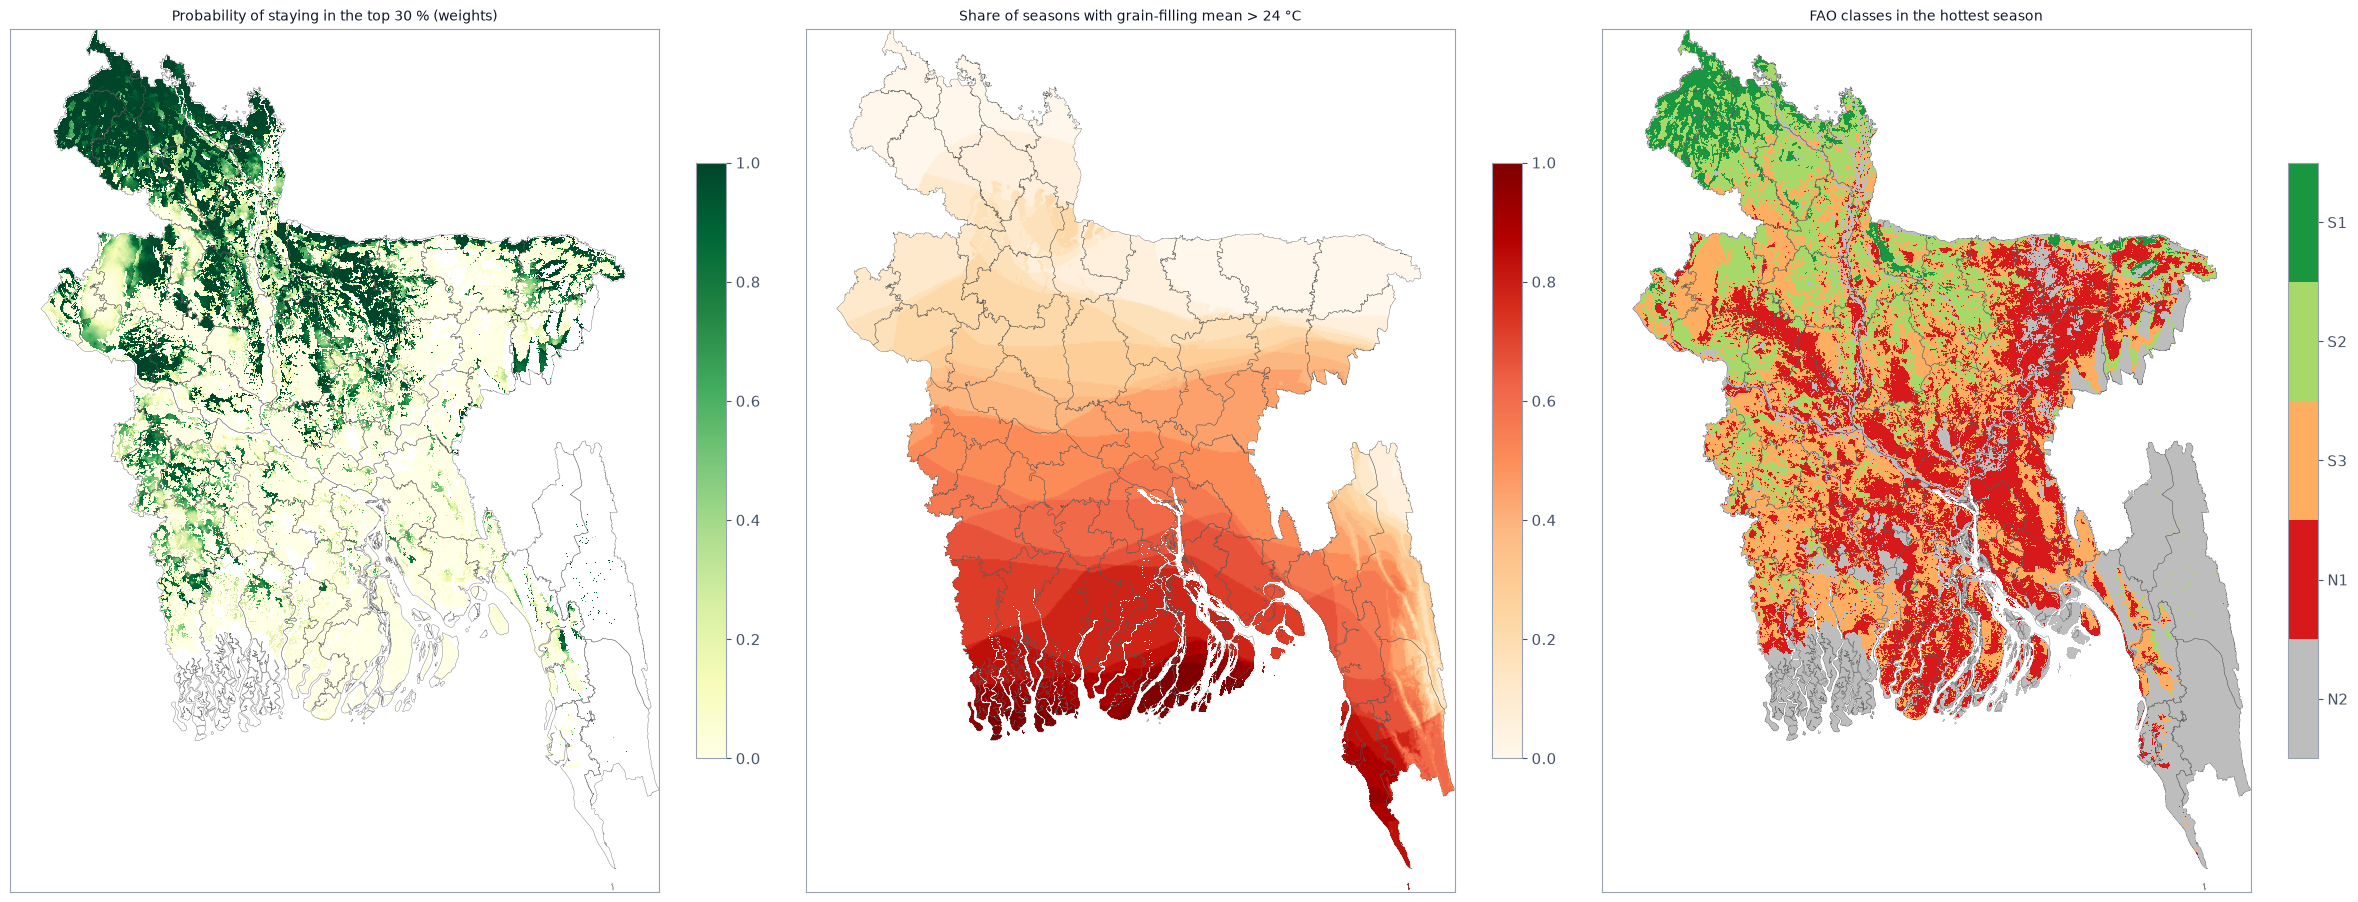

In [16]:
HOT = 24.0
hot_share1 = np.mean(GF_YEARS > HOT, axis=0)
HOT_SHARE = dp.warp_to_grid(to_mem(np.where(LAND1, hot_share1, np.nan)), GRID, resample="bilinear")
hottest = int(np.argmax(nat))
hot_gf = dp.warp_to_grid(to_mem(GF_YEARS[hottest]), GRID, resample="bilinear")
hot_members = dict(MEMBERS)
hot_members["grainfill_T"] = np.where(OK, np.clip(linear(hot_gf, 27.0, 21.0), 0, 1), np.nan)
hot_cls = fao_classes(combine(hot_members, W_AHP)["WLC"])
print(f"Hottest grain-filling period: {list(SEASONS)[hottest] - 1}/{list(SEASONS)[hottest]} "
      f"(national mean {nat[hottest]:.1f} °C vs {nat.mean():.1f} °C on average)")
comp = pd.DataFrame({"average season": [np.sum(CLS == i) * 0.0625 for i in range(5)],
                     "hottest season": [np.sum(hot_cls == i) * 0.0625 for i in range(5)]}, index=CLASS_NAMES)
display(comp.round(0).rename_axis(columns="km²"))

print("Jaccard index of class masks:")
for a, b in [("WLC (headline)", "Gamma"), ("WLC (headline)", "Minimum"), ("WLC (headline)", "WLC, strict water criteria")]:
    print(f"  S1+S2, {a} vs {b}: {jaccard_index(RUNS[a][1] >= 3, RUNS[b][1] >= 3):.2f}")
print(f"  S1+S2, average vs hottest season: {jaccard_index(CLS >= 3, hot_cls >= 3):.2f}")
for brk in [(0.58, 0.68, 0.78), (0.62, 0.72, 0.82)]:
    print(f"  S1+S2, breaks {BREAKS} vs {brk}: {jaccard_index(CLS >= 3, fao_classes(SCORES['WLC'], brk) >= 3):.2f}")

fig, axes = plt.subplots(1, 3, figsize=(24, 9))
im = show(axes[0], P_TOP, "Probability of staying in the top 30 % (weights)", "YlGn", 0, 1)
plt.colorbar(im, ax=axes[0], fraction=0.04)
im = show(axes[1], HOT_SHARE, f"Share of seasons with grain-filling mean > {HOT:.0f} °C", "OrRd", 0, 1)
plt.colorbar(im, ax=axes[1], fraction=0.04)
im = show(axes[2], hot_cls, "FAO classes in the hottest season", CLASS_CMAP, -0.5, 4.5)
cb = plt.colorbar(im, ax=axes[2], fraction=0.04, ticks=range(5))
cb.ax.set_yticklabels(CLASS_NAMES)
plt.tight_layout()
plt.show()

**Reading the uncertainty.** The weights matter moderately: a typical random weight vector keeps about 80 % of the baseline top-30 % set, and the core of the north-west stays in it under almost every vector. Moving the class break points by 0.02 keeps 85 to 88 % of the S1 + S2 land. The combination rule matters much more: the minimum rule shares only about a fifth of its S1 + S2 land with WLC, because it ignores everything except the weakest criterion. **Heat is the largest source of year-to-year risk.** In the hottest season of the record (2005/06), S1 + S2 land shrinks from about 49,600 to 28,400 km², and the share of seasons above 24 °C rises steadily from the north-west, where it is near zero, to the coast, where it is nearly every season. That is the practical case for early sowing and heat-tolerant varieties outside the north-west. (The straight-edged contours in the heat map are already in the source grids: the reanalysis was interpolated to 1 km by triangulation before export.)

## District and upazila summaries

In [17]:
rows = []
for i, r in enumerate(dist.itertuples(), start=1):
    m = (DIST_ID == i) & LAND
    rows.append((r.ADM2_EN, m.sum() * 0.0625, *[np.sum(CLS[m] == c) * 0.0625 for c in (4, 3, 2)],
                 np.nanmean(SCORES["WLC"][m & OK]) if (m & OK).any() else np.nan, r.ADM2_EN in MAJOR))
DIST_SUM = pd.DataFrame(rows, columns=["district", "land_km2", "S1_km2", "S2_km2", "S3_km2", "mean_wlc", "major_wheat"])
DIST_SUM["S1_S2_pct"] = (DIST_SUM.S1_km2 + DIST_SUM.S2_km2) / DIST_SUM.land_km2 * 100
DIST_SUM = DIST_SUM.sort_values("S1_S2_pct", ascending=False).reset_index(drop=True)
display(DIST_SUM.head(15).round(1))

rows = []
for i, r in enumerate(upz.itertuples(), start=1):
    m = (UPZ_ID == i) & LAND
    if m.sum() == 0:
        continue
    rows.append((r.ADM3_EN, r.ADM2_EN, m.sum() * 0.0625, np.sum(CLS[m] == 4) * 0.0625, np.sum(CLS[m] >= 3) * 0.0625))
UPZ_SUM = pd.DataFrame(rows, columns=["upazila", "district", "land_km2", "S1_km2", "S1_S2_km2"])
UPZ_SUM["S1_S2_pct"] = UPZ_SUM.S1_S2_km2 / UPZ_SUM.land_km2 * 100
print("Upazilas with the largest area of S1 + S2 land:")
display(UPZ_SUM.sort_values("S1_S2_km2", ascending=False).head(15).round(1).reset_index(drop=True))

,district,land_km2,S1_km2,S2_km2,S3_km2,mean_wlc,major_wheat,S1_S2_pct
0,Rangpur,2342.8,732.1,1532.1,8.9,0.8,False,96.6
1,Thakurgaon,1812.0,1353.6,384.7,6.1,0.8,True,95.9
2,Nilphamari,1587.7,823.3,696.1,4.7,0.8,False,95.7
3,Panchagarh,1361.2,1105.3,153.4,0.9,0.9,True,92.5
4,Dinajpur,3457.9,1336.4,1670.5,381.9,0.8,True,87.0
5,Lalmonirhat,1243.3,575.2,442.7,19.2,0.8,False,81.9
6,Sherpur,1321.1,394.1,684.0,123.3,0.8,False,81.6
7,Gaibandha,2164.2,343.8,1349.1,208.1,0.7,False,78.2
8,Bogra,2911.2,411.7,1788.4,498.9,0.7,False,75.6
9,Mymensingh,4345.3,1182.6,1974.0,863.5,0.7,False,72.6


Upazilas with the largest area of S1 + S2 land:


,upazila,district,land_km2,S1_km2,S1_S2_km2,S1_S2_pct
0,Thakurgaon Sadar,Thakurgaon,693.0,593.9,690.1,99.6
1,Mitha Pukur,Rangpur,519.5,153.8,516.6,99.4
2,Phulpur,Mymensingh,567.9,346.4,433.8,76.4
3,Birganj,Dinajpur,415.0,328.6,413.2,99.6
4,Gobindaganj,Gaibandha,467.8,96.8,402.4,86.0
5,Pirganj,Rangpur,409.1,134.6,397.6,97.2
6,Jamalpur Sadar,Jamalpur,495.8,147.7,387.8,78.2
7,Godagari,Rajshahi,491.4,0.0,386.8,78.7
8,Patnitala,Naogaon,387.4,1.4,380.8,98.3
9,Parbatipur,Dinajpur,394.2,83.3,368.3,93.4


## Outputs

All rasters are GeoTIFFs on the national 250 m grid in `Data/03_spatial_analysis/capstone_spatial_analysis/wheat_suitability/`.

In [18]:
for k, v in CLIM.items():
    GRID.write(OUT / f"{k}_corrected_250m.tif", np.where(LAND, v, np.nan))
for k, v in MEMBERS.items():
    GRID.write(OUT / f"membership_{k}_250m.tif", v)
for k, v in SCORES.items():
    GRID.write(OUT / f"suitability_{k}_250m.tif", v)
GRID.write(OUT / "fao_class_wlc_250m.tif", CLS)
GRID.write(OUT / "limiting_factor_250m.tif", LIMIT)
GRID.write(OUT / "p_top30_weights_250m.tif", P_TOP)
GRID.write(OUT / "hot_season_share_250m.tif", np.where(LAND, HOT_SHARE, np.nan))
GRID.write(OUT / "fao_class_hottest_season_250m.tif", hot_cls)
pd.Series(dict(enumerate(CRITERIA)), name="criterion").to_csv(OUT / "limiting_factor_codes.csv")
pd.Series(dict(enumerate(CLASS_NAMES)), name="class").to_csv(OUT / "fao_class_codes.csv")
W_AHP.rename("weight").to_csv(OUT / "ahp_weights.csv")
DIST_SUM.to_csv(OUT / "district_summary.csv", index=False)
UPZ_SUM.to_csv(OUT / "upazila_summary.csv", index=False)
dist.merge(DIST_SUM, left_on="ADM2_EN", right_on="district").to_file(OUT / "district_summary.gpkg", driver="GPKG")
for p in sorted(OUT.glob("*.*")):
    print(f"{p.name:45s} {p.stat().st_size / 1024:8.0f} KB")

ahp_weights.csv                                      0 KB
district_summary.csv                                 5 KB
district_summary.gpkg                            16792 KB
fao_class_codes.csv                                  0 KB
fao_class_hottest_season_250m.tif                20122 KB
fao_class_wlc_250m.tif                           20122 KB
grainfill_T_corrected_250m.tif                   20122 KB
hot_season_share_250m.tif                        20122 KB
limiting_factor_250m.tif                         20122 KB
limiting_factor_codes.csv                            0 KB
membership_OC_250m.tif                           20122 KB
membership_drainage_250m.tif                     20122 KB
membership_drought_250m.tif                      20122 KB
membership_grainfill_T_250m.tif                  20122 KB
membership_irrigation_250m.tif                   20122 KB
membership_land_type_250m.tif                    20122 KB
membership_pH_250m.tif                           20122 KB
membership_sea

## Limitations

- **Temperature grids.** The stored files are upside down. The correction recovers two thirds of the land cells exactly and fills the rest from a smooth trend; it is accurate to a few hundredths of a degree in a hold-out test, but the files should be re-exported. Only mean temperature is usable; the `mn2t` and `mx2t` grids are hourly extremes, so daily-maximum heat rules cannot be applied.
- **Salinity is missing.** Large parts of the south-western and south-central coast are saline in the dry season, which rules out wheat. No salinity map is in the folder, so the coastal classes are too optimistic where salinity, not temperature, is the binding limit.
- **Soil maps are generalised.** Land type, drainage, pH and organic carbon come from the national soil survey at reconnaissance scale. A 250 m cell carries the dominant class of a mapping unit, not the field.
- **Water.** The water table is from one year (2020) and does not include surface-water irrigation or the cost of pumping.
- **Validation is coarse.** The reference is a list of districts, not wheat fields, and it mixes suitability with economics. District statistics of wheat area (BBS) or a wheat map from Sentinel-2 would allow a much sharper test.
- **Unused layers.** Texture has no legend; permeability, depth class and thermal zone are undocumented or redundant.

## Where to go next

- Re-export the 2000 to 2018 temperature composites with the latitude axis handled correctly and rerun without `correct`.
- Add a **soil salinity** layer (SRDI) as a constraint or criterion for the coastal districts.
- Validate against **upazila wheat area** from the BBS Yearbook of Agricultural Statistics, or against a wheat map classified from Sentinel-2 time series in February.
- Model **sowing date**: flood recession from Sentinel-1 in October and November decides when each field can be sown, and therefore how much March heat the crop meets.
- Add **wheat blast** risk zones for the south-western districts affected since 2016.
- Repeat the analysis for **maize**, which competes with wheat for the same land in the same season, and map where each crop has the advantage.